# Pipeline stage analysis — v3 (deterministic pass selection)

Analyzes the masking passes for the 4 methodology stages:
**Tracking → Annotator 1 → Annotator 2 → Final (validated)**.

**Data:** `new_mascaramento/new_data/masks_data/` (30 videos, batches L2 to L5).
The mask data is not released in this repository (it can be derived from the
dataset or made available upon request); this notebook is kept to document and reproduce the computation once the
data is in place (`DATA_DIR`).

## How accuracy is computed

The paper metric (Eq. 1) is a **simple count**:

$$\text{accuracy} = \frac{\text{masks in the pass}}{\text{masks in the final pass}}$$

The final pass (label) is the reference, so its accuracy is 100% by definition.

**Why can it exceed 100%?** Because it is a count, not matching: if a pass has MORE
masks than the label (e.g. tracking with false positives that validation later removes,
like L4 [16] at 106%), the ratio exceeds 100%. This is over-masking, not a computation
error. As an additional reference, `per_pass.csv` also carries the IoU-matching accuracy
(`accuracy` = TP/label with IoU ≥ 0.5), which never exceeds 100%.

## Pass selection logic (v3, deterministic)

The JSONL files carry ALL persisted saves, including intermediate autosaves, and there
is no metadata about who produced each pass. v2 used a manual per-video mapping; v3
replaces it with a single rule applied to all:

1. **pass0 = Tracking** (the first pass is always the automatic model output).
   Exception: if pass0 is **truncated** (covers less than 90% of the video frames,
   the case of L2 [004] whose export stopped at frame 3428 of 27725), the Tracking
   stage is marked as **not recoverable** for that video.
2. **Last pass = Final** (label, reference of Eq. 1).
3. **Inflated intermediate passes are discarded**: an intermediate with more than
   110% of the label masks is an autosave captured IN THE MIDDLE of a manual edit,
   with interpolation in progress (e.g. L5 [001] p1 = 29603 tracked + 16780
   interpolated + 1 manual; the next pass trims to 913 interpolated). It is not a
   methodology stage.
4. **Consecutive passes with the SAME mask count are collapsed**, keeping the last
   of the sequence (equal count = no net edit = autosave).
5. Of the remaining intermediates, the assignment is done **from the end to the start**:
   the last one before Final = **Annot2** (reflects the accumulated work of the two
   annotators), the previous one = **Annot1**. Older leftover intermediates are
   unassigned autosaves.
6. If only ONE intermediate remains, it becomes Annot2 and **Annot1 is not recoverable**
   (we know two annotators worked, but only one snapshot was persisted).
   If none remains, both annotation stages are not recoverable.
7. Videos with a single pass (tracking only, no annotation: L5 [006] and L5 [012]) are
   **excluded**, as they have no label to compare against.

Not-recoverable stages enter as NaN: the video still participates in the other stages and
each stage's N is reported separately.

**Outputs** (in `stage_analysis_out/`): `per_pass.csv`, `selection_v3.csv`,
`excluded_videos.csv`, `paper_stage_table.csv`, `paper_stage_general.csv`,
`paper_stage_by_video.csv`, `paper_stage_by_video_detailed.csv`,
`paper_stage_by_batch.csv`, `stage_progression_v3.png`, `stage_heatmap_v3.png`,
and the LaTeX ready for `tab:stagesgeneral`, `tab:stages`, `tab:stagesvideo`.

In [1]:
import collections, glob, json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

DATA_DIR = os.environ.get('HIAAC_MASKS_DATA', '../../new_mascaramento/new_data/masks_data')
OUT_DIR  = 'stage_analysis_out'
IOU_THR  = 0.5
ROLES    = ['Tracking', 'Annot1', 'Annot2', 'Final']

INFLATED_THR = 1.10   # intermediate with masks > 110% of label = edit autosave
TRUNC_THR    = 0.90   # pass0 covering < 90% of label frames = truncated tracking

os.makedirs(OUT_DIR, exist_ok=True)

## 1. Per-pass metrics (per_pass.csv)

For each video, the last pass is the label. Each pass is compared to the label in two
ways:
- `count_pct` = pass masks / label masks (Eq. 1 of the paper, may exceed 100%)
- `accuracy` = TP / label with IoU ≥ 0.5 matching (capped at 100%)

If `per_pass.csv` already exists and `RECOMPUTE=False`, it is loaded from disk (the IoU
computation is slow).

In [2]:
def load_jsonl(path):
    fr = {}
    with open(path) as fh:
        for line in fh:
            d = json.loads(line)
            fr[d['frame']] = [(m['x'], m['y'], m['w'], m['h']) for m in d.get('masks', [])]
    return fr

def iou(a, b):
    ix1 = max(a[0], b[0]); iy1 = max(a[1], b[1])
    ix2 = min(a[0]+a[2], b[0]+b[2]); iy2 = min(a[1]+a[3], b[1]+b[3])
    iw = max(0, ix2-ix1); ih = max(0, iy2-iy1)
    inter = iw * ih
    ua = a[2]*a[3] + b[2]*b[3] - inter
    return inter / ua if ua > 0 else 0.0

def match(pred, gt, thr=IOU_THR):
    used, tp = set(), 0
    for p in pred:
        best, bi = -1.0, -1
        for j, g in enumerate(gt):
            if j in used: continue
            v = iou(p, g)
            if v > best: best, bi = v, j
        if best >= thr and bi >= 0:
            used.add(bi); tp += 1
    return tp, len(pred) - tp, len(gt) - tp

def group_files(folder):
    groups = collections.defaultdict(list)
    for f in glob.glob(os.path.join(folder, '*.jsonl')):
        stem = os.path.basename(f)
        base = stem.rsplit('_pass', 1)[0]
        p = int(stem.rsplit('_pass', 1)[1].split('.')[0])
        groups[base].append((p, f))
    for lst in groups.values():
        lst.sort()
    return groups

groups = group_files(DATA_DIR)
print(f'{len(groups)} videos, {sum(len(v) for v in groups.values())} pass files')

30 videos, 129 pass files


In [3]:
RECOMPUTE = False  # True to force recomputation

per_pass_path = os.path.join(OUT_DIR, 'per_pass.csv')
if os.path.exists(per_pass_path) and not RECOMPUTE:
    per_pass = pd.read_csv(per_pass_path)
    print(f'Loaded per_pass.csv: {len(per_pass)} rows, {per_pass.video.nunique()} videos')
else:
    rows = []
    n_total = sum(len(v) for v in groups.values())
    done = 0
    for base, lst in sorted(groups.items()):
        short = base.split('_video_')[0]
        label_p, label_f = lst[-1]
        gt = load_jsonl(label_f)
        gt_total = sum(len(v) for v in gt.values())
        for p, f in lst:
            pr = load_jsonl(f)
            nmask = sum(len(v) for v in pr.values())
            TP = FP = FN = 0
            for fr, gboxes in gt.items():
                tp, fp, fn = match(pr.get(fr, []), gboxes)
                TP += tp; FP += fp; FN += fn
            rows.append(dict(video=short, pass_k=p, is_label=(p == label_p),
                             masks=nmask, label_total=gt_total,
                             count_pct=round(100*nmask/gt_total, 1) if gt_total else 0,
                             TP=TP, FP=FP, FN=FN,
                             accuracy=round(100*TP/gt_total, 1) if gt_total else 0))
            done += 1
            if done % 10 == 0 or done == n_total:
                print(f'  [{done}/{n_total}] {short} pass{p}')
    per_pass = pd.DataFrame(rows)
    per_pass.to_csv(per_pass_path, index=False)
    print(f'Saved per_pass.csv: {len(per_pass)} rows')

Loaded per_pass.csv: 129 rows, 30 videos


## 2. pass0 truncation check

Compares the last frame WITH a mask in pass0 against the label's. If pass0 covers less
than 90% of the video, the tracking file is truncated (incomplete export) and the
Tracking stage is not recoverable for that video.

Known case: **L2 [004]**, whose pass0 stops at frame 3428 of 27725 (12% of the video).
That is why it showed 12.8% accuracy in v2: not a model failure, an incomplete file
(all 3429 masks present match the label, TP=3429, FP=0).

In [4]:
def last_masked_frame(path):
    last = -1
    with open(path) as fh:
        for line in fh:
            d = json.loads(line)
            if d.get('masks'):
                last = max(last, d['frame'])
    return last

cov_rows = []
for base, lst in sorted(groups.items()):
    short = base.split('_video_')[0]
    if len(lst) < 2:
        continue  # single-pass video is handled in the exclusion
    p0_last = last_masked_frame(lst[0][1])
    lbl_last = last_masked_frame(lst[-1][1])
    ratio = p0_last / lbl_last if lbl_last > 0 else 0
    cov_rows.append(dict(video=short, p0_last_frame=p0_last,
                         label_last_frame=lbl_last,
                         coverage=round(ratio, 3),
                         truncated=(ratio < TRUNC_THR)))
coverage = pd.DataFrame(cov_rows)
TRUNCATED = set(coverage[coverage.truncated].video)
print('Videos with truncated pass0:', TRUNCATED or 'none')
coverage[coverage.truncated | (coverage.coverage < 0.99)]

Videos with truncated pass0: {'L2 [all] [004]'}


,video,p0_last_frame,label_last_frame,coverage,truncated
1,L2 [all] [004],3428,27724,0.124,True


## 3. Deterministic pass selection (v3 rule)

Implements the logic described in the introduction. The printed table shows, per video,
which raw pass was assigned to each stage and what was discarded (with the reason).

In [5]:
def select_passes(vdf, truncated_p0=False):
    """v3 rule. Returns (dict role->pass_k or None, list of notes)."""
    vdf = vdf.sort_values('pass_k').reset_index(drop=True)
    label_total = vdf.label_total.iloc[0]
    passes = list(vdf.itertuples())
    notes = []
    if len(passes) == 1:
        return None, ['only 1 pass (no annotation, no label)']

    sel = {r: None for r in ROLES}
    # 1. pass0 = Tracking (unless truncated)
    if truncated_p0:
        notes.append('Tracking NOT RECOVERABLE (truncated pass0)')
    else:
        sel['Tracking'] = passes[0].pass_k
    # 2. last = Final
    sel['Final'] = passes[-1].pass_k

    inter = passes[1:-1]
    # 3. discard inflated intermediates (autosave in the middle of a manual edit)
    inflated = [p for p in inter if p.masks > INFLATED_THR * label_total]
    inter = [p for p in inter if p.masks <= INFLATED_THR * label_total]
    if inflated:
        notes.append('inflated discarded: ' + ', '.join(
            f'p{p.pass_k} ({100*p.masks/label_total:.0f}%)' for p in inflated))
    # 4. collapse consecutive equal counts, keeping the last
    collapsed = []
    for p in inter:
        if collapsed and collapsed[-1].masks == p.masks:
            collapsed[-1] = p
        else:
            collapsed.append(p)
    if len(collapsed) < len(inter):
        notes.append(f'{len(inter)-len(collapsed)} pass(es) collapsed by equal count')
    inter = collapsed
    # 5/6. assignment from the end to the start
    if len(inter) >= 2:
        sel['Annot2'] = inter[-1].pass_k
        sel['Annot1'] = inter[-2].pass_k
        if len(inter) > 2:
            notes.append('unassigned autosaves: ' + ', '.join(f'p{p.pass_k}' for p in inter[:-2]))
    elif len(inter) == 1:
        sel['Annot2'] = inter[-1].pass_k
        notes.append('Annot1 NOT RECOVERABLE (only one intermediate persisted)')
    else:
        notes.append('Annot1 and Annot2 NOT RECOVERABLE (no intermediate)')
    return sel, notes


sel_records, excluded_records = [], []
for video in sorted(per_pass.video.unique()):
    vdf = per_pass[per_pass.video == video]
    sel, notes = select_passes(vdf, truncated_p0=(video in TRUNCATED))
    if sel is None:
        excluded_records.append(dict(video=video, reason='; '.join(notes)))
        continue
    batch = video.split(' ')[0]
    for role in ROLES:
        k = sel[role]
        if k is None:
            sel_records.append(dict(video=video, batch=batch, role=role, raw_pass=np.nan,
                                    masks=np.nan, label_total=int(vdf.label_total.iloc[0]),
                                    notes='; '.join(notes)))
        else:
            r = vdf[vdf.pass_k == k].iloc[0]
            sel_records.append(dict(video=video, batch=batch, role=role, raw_pass=k,
                                    masks=int(r.masks), label_total=int(r.label_total),
                                    notes='; '.join(notes)))

sel_df = pd.DataFrame(sel_records)
sel_df['role'] = pd.Categorical(sel_df.role, categories=ROLES, ordered=True)
sel_df['accuracy_pct'] = (100 * sel_df.masks / sel_df.label_total).round(2)
sel_df['missing'] = (sel_df.label_total - sel_df.masks).clip(lower=0)

excl = pd.DataFrame(excluded_records)
excl.to_csv(os.path.join(OUT_DIR, 'excluded_videos.csv'), index=False)
sel_df.to_csv(os.path.join(OUT_DIR, 'selection_v3.csv'), index=False)

N = sel_df.video.nunique()
print(f'Included: {N} videos | Excluded: {len(excl)}')
print()
print('=== EXCLUDED ===')
display(excl)
print('=== MAPPING (raw pass per stage; -- = not recoverable) ===')
mapping = (sel_df.pivot_table(index='video', columns='role', values='raw_pass',
                              observed=True, aggfunc='first')
           .reindex(columns=ROLES))
mapping_disp = mapping.map(lambda v: f'p{int(v)}' if pd.notna(v) else '--')
mapping_disp['notes'] = sel_df.groupby('video').notes.first()
display(mapping_disp)

Included: 28 videos | Excluded: 2

=== EXCLUDED ===


,video,reason
0,L5 [all] [006],"only 1 pass (no annotation, no label)"
1,L5 [all] [012],"only 1 pass (no annotation, no label)"


=== MAPPING (raw pass per stage; -- = not recoverable) ===


role,Tracking,Annot1,Annot2,Final,notes
video,,,,,
L2 [all] [001],p0,p3,p4,p5,"unassigned autosaves: p1, p2"
L2 [all] [004],--,p1,p2,p3,Tracking NOT RECOVERABLE (truncated pass0)
L2 [all] [005],p0,p1,p2,p3,
L2 [all] [007],p0,p3,p4,p5,"unassigned autosaves: p1, p2"
L2 [all] [008],p0,--,p1,p2,Annot1 NOT RECOVERABLE (only one intermediate ...
L3 [all] [01],p0,p1,p2,p3,
L3 [all] [03],p0,p2,p3,p4,1 pass(es) collapsed by equal count
L3 [all] [06],p0,p5,p6,p7,1 pass(es) collapsed by equal count; unassigne...
L3 [all] [09],p0,p1,p2,p3,


## 4. Aggregated tables per stage

Each stage's aggregated accuracy is the Eq. 1 micro-average: the sum of the stage masks
divided by the sum of the labels, **considering only the videos where the stage is
recoverable** (hence N varies per stage). The standard deviation is that of the per-video
accuracy.

In [6]:
valid = sel_df.dropna(subset=['masks']).copy()

g = valid.groupby('role', observed=True)
overall = g.agg(
    masks=('masks', 'sum'),
    label_total=('label_total', 'sum'),
    missing=('missing', 'sum'),
    acc_std=('accuracy_pct', lambda s: s.std(ddof=1)),
).reindex(ROLES)
overall['n_videos'] = g.video.nunique().reindex(ROLES)
overall['accuracy_pct'] = (100 * overall.masks / overall.label_total).round(2)
overall['acc_std'] = overall.acc_std.round(2)
overall = overall.reset_index()[['role','n_videos','masks','label_total','accuracy_pct','acc_std','missing']]
overall[['masks','label_total','missing','n_videos']] = overall[['masks','label_total','missing','n_videos']].astype(int)
overall.to_csv(os.path.join(OUT_DIR, 'paper_stage_table.csv'), index=False)

general = overall[overall.role.isin(['Tracking','Final'])].copy()
general['role'] = general.role.map({'Tracking': 'Automatic', 'Final': 'Final (validated)'})
general = general[['role','n_videos','masks','accuracy_pct','acc_std']]
general.to_csv(os.path.join(OUT_DIR, 'paper_stage_general.csv'), index=False)

by_video = (sel_df.pivot_table(index='video', columns='role', values='accuracy_pct', observed=True)
            .reindex(columns=ROLES).round(2).reset_index())
by_video.to_csv(os.path.join(OUT_DIR, 'paper_stage_by_video.csv'), index=False)

detailed = sel_df[['video','batch','role','raw_pass','masks','accuracy_pct','missing','notes']].copy()
detailed.to_csv(os.path.join(OUT_DIR, 'paper_stage_by_video_detailed.csv'), index=False)

gb = valid.groupby(['batch','role'], observed=True)
by_batch = gb.agg(n_videos=('video','nunique'), masks=('masks','sum'),
                  label_total=('label_total','sum')).reset_index()
by_batch['accuracy_pct'] = (100 * by_batch.masks / by_batch.label_total).round(2)
by_batch.to_csv(os.path.join(OUT_DIR, 'paper_stage_by_batch.csv'), index=False)

print('=== PER STAGE (N varies: not-recoverable stages are excluded) ===')
display(overall)
print('=== GENERAL (Tracking vs Final) ===')
display(general)
print('=== PER BATCH ===')
display(by_batch.pivot_table(index='batch', columns='role', values='accuracy_pct', observed=True)
        .reindex(columns=ROLES))

=== PER STAGE (N varies: not-recoverable stages are excluded) ===


,role,n_videos,masks,label_total,accuracy_pct,acc_std,missing
0,Tracking,27,1091382,1156280,94.39,4.82,68148
1,Annot1,26,1091232,1107315,98.55,2.70,18347
2,Annot2,28,1180228,1183065,99.76,1.10,4835
3,Final,28,1183065,1183065,100.00,0.00,0


=== GENERAL (Tracking vs Final) ===


,role,n_videos,masks,accuracy_pct,acc_std
0,Automatic,27,1091382,94.39,4.82
3,Final (validated),28,1183065,100.00,0.00


=== PER BATCH ===


role,Tracking,Annot1,Annot2,Final
batch,,,,
L2,95.55,98.78,99.95,100.0
L3,94.48,96.97,98.98,100.0
L4,95.83,99.65,100.48,100.0
L5,92.69,99.28,99.88,100.0


## 5. Plots

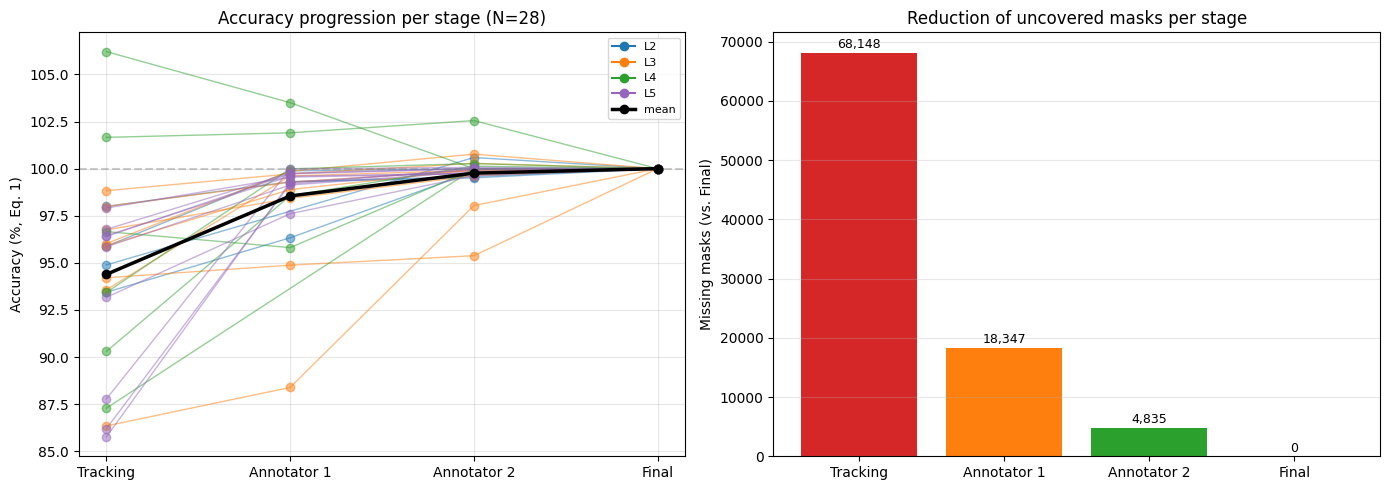

Saved stage_progression_v3.png


In [7]:
batch_colors = {'L2': '#1f77b4', 'L3': '#ff7f0e', 'L4': '#2ca02c', 'L5': '#9467bd'}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
x_roles = {r: i for i, r in enumerate(ROLES)}
for _, vdf in sel_df.groupby('video'):
    batch = vdf.batch.iloc[0]
    pts = vdf.dropna(subset=['accuracy_pct'])
    xs = [x_roles[r] for r in pts.role]
    ys = pts.accuracy_pct.values
    ax.plot(xs, ys, marker='o', color=batch_colors[batch], alpha=0.5, linewidth=1)
ax.plot(range(4), overall.accuracy_pct.values, 'k-o', linewidth=2.5, zorder=5)
ax.set_xticks(range(4))
ax.set_xticklabels(['Tracking', 'Annotator 1', 'Annotator 2', 'Final'])
ax.set_ylabel('Accuracy (%, Eq. 1)')
ax.set_title(f'Accuracy progression per stage (N={N})')
ax.axhline(100, color='gray', linestyle='--', alpha=0.4)
ax.grid(alpha=0.3)
from matplotlib.lines import Line2D
handles = [Line2D([0],[0], color=c, marker='o', label=b) for b, c in batch_colors.items()]
handles.append(Line2D([0],[0], color='k', marker='o', linewidth=2.5, label='mean'))
ax.legend(handles=handles, fontsize=8)

ax2 = axes[1]
stage_labels = ['Tracking', 'Annotator 1', 'Annotator 2', 'Final']
missing_vals = overall.missing.values
bars = ax2.bar(stage_labels, missing_vals, color=['#d62728','#ff7f0e','#2ca02c','#1f77b4'])
for bar, val in zip(bars, missing_vals):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 200,
             f'{val:,}', ha='center', va='bottom', fontsize=9)
ax2.set_ylabel('Missing masks (vs. Final)')
ax2.set_title('Reduction of uncovered masks per stage')
ax2.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'stage_progression_v3.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Saved stage_progression_v3.png')

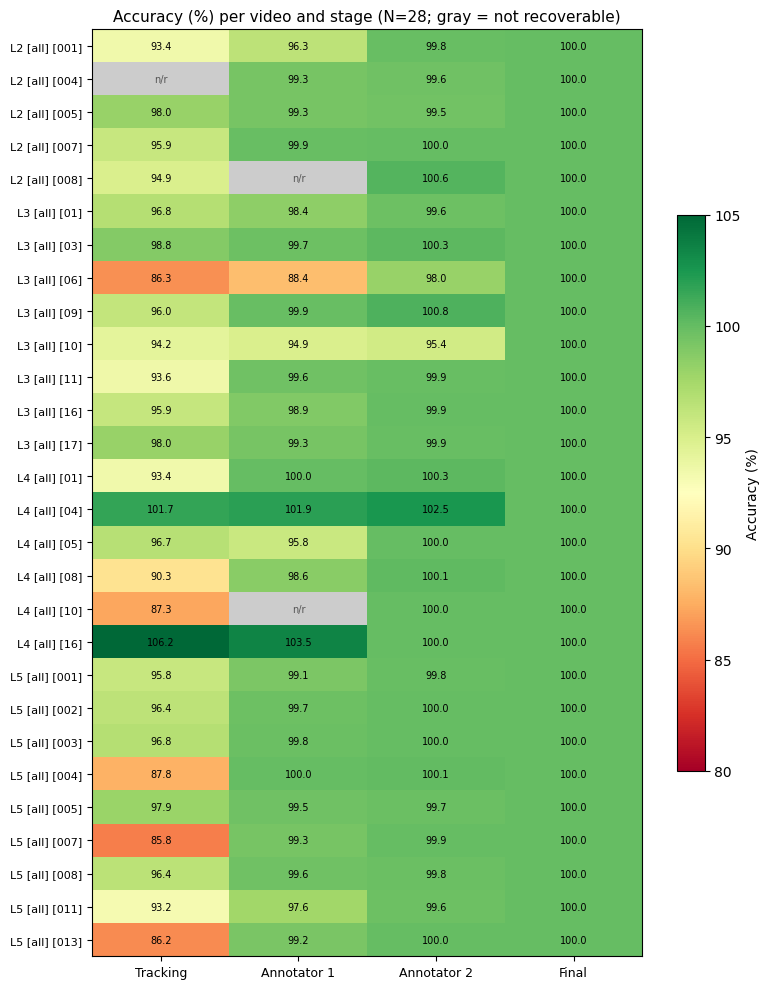

Saved stage_heatmap_v3.png


In [8]:
pivot = by_video.set_index('video')[ROLES]
vals = np.ma.masked_invalid(pivot.clip(upper=105).values)

fig, ax = plt.subplots(figsize=(8, 10))
cmap = plt.cm.RdYlGn.copy()
cmap.set_bad('#cccccc')  # not-recoverable stage = gray
im = ax.imshow(vals, cmap=cmap, vmin=80, vmax=105, aspect='auto')

ax.set_xticks(range(4))
ax.set_xticklabels(['Tracking', 'Annotator 1', 'Annotator 2', 'Final'], fontsize=9)
ax.set_yticks(range(len(pivot)))
ax.set_yticklabels(pivot.index, fontsize=8)
ax.set_title(f'Accuracy (%) per video and stage (N={N}; gray = not recoverable)', fontsize=11)

for i in range(len(pivot)):
    for j in range(4):
        val = pivot.values[i, j]
        if pd.isna(val):
            ax.text(j, i, 'n/r', ha='center', va='center', fontsize=7, color='#555555')
        else:
            ax.text(j, i, f'{val:.1f}', ha='center', va='center', fontsize=7,
                    color='black')

plt.colorbar(im, ax=ax, label='Accuracy (%)', shrink=0.6)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'stage_heatmap_v3.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Saved stage_heatmap_v3.png')

## 6. LaTeX ready for the paper

Replaces the `tab:stagesgeneral`, `tab:stages` and `tab:stagesvideo` tables in
`tex/validation.tex`. Each stage's N may differ (not-recoverable stages).

In [9]:
def fmt_masks(n):
    return f'{int(n):,}'.replace(',', '\\,')

auto_row = overall[overall.role == 'Tracking'].iloc[0]
fin_row  = overall[overall.role == 'Final'].iloc[0]

latex_general = f"""\\begin{{table}}[ht]
\\centering
\\small
\\caption{{General result: automatic masking versus the final validated reference,
over the fully annotated videos of batches L2 to L5. Accuracy is
Equation~\\ref{{eq:acc}} (total masks divided by total label masks) with the standard
deviation across videos. $N$ differs per stage because the tracking export of one
video is truncated and its automatic stage cannot be recovered.}}
\\label{{tab:stagesgeneral}}
\\begin{{tabular}}{{@{{}}lrrr@{{}}}}
\\toprule
\\textbf{{Stage}} & \\textbf{{$N$}} & \\textbf{{Masks}} & \\textbf{{Accuracy (Eq.~\\ref{{eq:acc}})}} \\\\
\\midrule
Automatic (YOLOv7-tiny) & {int(auto_row.n_videos)} & {fmt_masks(auto_row.masks)} & ${auto_row.accuracy_pct:.2f} \\pm {auto_row.acc_std:.2f}\\,\\%$ \\\\
Final (validated)       & {int(fin_row.n_videos)} & {fmt_masks(fin_row.masks)} & ${fin_row.accuracy_pct:.2f} \\pm {fin_row.acc_std:.2f}\\,\\%$ \\\\
\\bottomrule
\\end{{tabular}}
\\end{{table}}"""

print(latex_general)

\begin{table}[ht]
\centering
\small
\caption{General result: automatic masking versus the final validated reference,
over the fully annotated videos of batches L2 to L5. Accuracy is
Equation~\ref{eq:acc} (total masks divided by total label masks) with the standard
deviation across videos. $N$ differs per stage because the tracking export of one
video is truncated and its automatic stage cannot be recovered.}
\label{tab:stagesgeneral}
\begin{tabular}{@{}lrrr@{}}
\toprule
\textbf{Stage} & \textbf{$N$} & \textbf{Masks} & \textbf{Accuracy (Eq.~\ref{eq:acc})} \\
\midrule
Automatic (YOLOv7-tiny) & 27 & 1\,091\,382 & $94.39 \pm 4.82\,\%$ \\
Final (validated)       & 28 & 1\,183\,065 & $100.00 \pm 0.00\,\%$ \\
\bottomrule
\end{tabular}
\end{table}


In [10]:
stage_labels_tex = {
    'Tracking': 'Automatic (YOLOv7-tiny)',
    'Annot1':   '+ Annotator~1',
    'Annot2':   '+ Annotator~2',
    'Final':    'Final (validated)',
}

rows_tex = []
for _, row in overall.iterrows():
    rows_tex.append(
        f'{stage_labels_tex[row.role]} & {int(row.n_videos)} & {fmt_masks(row.masks)} & '
        f'${row.accuracy_pct:.2f} \\pm {row.acc_std:.2f}$ & '
        f'{fmt_masks(row.missing)} \\\\'
    )
body = '\n'.join(rows_tex)

latex_stages = f"""\\begin{{table}}[ht]
\\centering
\\small
\\caption{{Masking results across the four pipeline stages (batches L2 to L5).
Accuracy is Equation~\\ref{{eq:acc}} $\\pm$ the standard deviation across videos;
\\emph{{missing}} is how many fewer masks than the final pass. $N$ differs per stage:
stages whose persisted pass could not be recovered (truncated tracking export, or a
single persisted annotation snapshot) are excluded for that video only.}}
\\label{{tab:stages}}
\\begin{{tabular}}{{@{{}}lrrrr@{{}}}}
\\toprule
\\textbf{{Stage}} & \\textbf{{$N$}} & \\textbf{{Masks}} & \\textbf{{Accuracy (\\%)}} & \\textbf{{Missing}} \\\\
\\midrule
{body}
\\bottomrule
\\end{{tabular}}
\\end{{table}}"""

print(latex_stages)

\begin{table}[ht]
\centering
\small
\caption{Masking results across the four pipeline stages (batches L2 to L5).
Accuracy is Equation~\ref{eq:acc} $\pm$ the standard deviation across videos;
\emph{missing} is how many fewer masks than the final pass. $N$ differs per stage:
stages whose persisted pass could not be recovered (truncated tracking export, or a
single persisted annotation snapshot) are excluded for that video only.}
\label{tab:stages}
\begin{tabular}{@{}lrrrr@{}}
\toprule
\textbf{Stage} & \textbf{$N$} & \textbf{Masks} & \textbf{Accuracy (\%)} & \textbf{Missing} \\
\midrule
Automatic (YOLOv7-tiny) & 27 & 1\,091\,382 & $94.39 \pm 4.82$ & 68\,148 \\
+ Annotator~1 & 26 & 1\,091\,232 & $98.55 \pm 2.70$ & 18\,347 \\
+ Annotator~2 & 28 & 1\,180\,228 & $99.76 \pm 1.10$ & 4\,835 \\
Final (validated) & 28 & 1\,183\,065 & $100.00 \pm 0.00$ & 0 \\
\bottomrule
\end{tabular}
\end{table}


In [11]:
role_tex = {'Tracking': 'Automatic', 'Annot1': 'Annotator~1',
            'Annot2': 'Annotator~2', 'Final': 'Final'}

lines = []
for video in sel_df.video.unique():
    vdf = sel_df[sel_df.video == video].sort_values('role')
    first = True
    for _, row in vdf.iterrows():
        v_col = video if first else ''
        if pd.isna(row.masks):
            lines.append(f'{v_col} & {role_tex[row.role]} & \\multicolumn{{3}}{{c}}{{not recoverable}} \\\\')
        else:
            over = '*' if row.accuracy_pct > 100 else ''
            lines.append(
                f'{v_col} & {role_tex[row.role]} & '
                f'{fmt_masks(row.masks)} & {row.accuracy_pct:.2f}\\,\\%{over} & '
                f'{fmt_masks(row.missing)} \\\\'
            )
        first = False
    lines.append('\\midrule')
if lines and lines[-1] == '\\midrule':
    lines[-1] = '\\bottomrule'
body_v = '\n'.join(lines)

latex_byvideo = f"""% Requires \\usepackage{{booktabs}} and \\usepackage{{longtable}}
\\begin{{longtable}}{{@{{}}llrrr@{{}}}}
\\caption{{Detailed per-video, per-stage masking results over the $N={N}$ videos.
Accuracy is Equation~\\ref{{eq:acc}} (masks relative to the label); \\emph{{missing}}
is how many fewer masks than the final pass. * marks passes with over-masking
(accuracy above $100\\,\\%$, later trimmed by validation); \\emph{{not recoverable}}
marks stages whose persisted pass could not be identified in the export.}}
\\label{{tab:stagesvideo}}\\\\
\\toprule
\\textbf{{Video}} & \\textbf{{Stage}} & \\textbf{{Masks}} & \\textbf{{Accuracy}} & \\textbf{{Missing}} \\\\
\\midrule
\\endfirsthead
\\multicolumn{{5}}{{c}}{{\\tablename\\ \\thetable\\ (continued)}} \\\\
\\toprule
\\textbf{{Video}} & \\textbf{{Stage}} & \\textbf{{Masks}} & \\textbf{{Accuracy}} & \\textbf{{Missing}} \\\\
\\midrule
\\endhead
{body_v}
\\end{{longtable}}"""

print(latex_byvideo)

% Requires \usepackage{booktabs} and \usepackage{longtable}
\begin{longtable}{@{}llrrr@{}}
\caption{Detailed per-video, per-stage masking results over the $N=28$ videos.
Accuracy is Equation~\ref{eq:acc} (masks relative to the label); \emph{missing}
is how many fewer masks than the final pass. * marks passes with over-masking
(accuracy above $100\,\%$, later trimmed by validation); \emph{not recoverable}
marks stages whose persisted pass could not be identified in the export.}
\label{tab:stagesvideo}\\
\toprule
\textbf{Video} & \textbf{Stage} & \textbf{Masks} & \textbf{Accuracy} & \textbf{Missing} \\
\midrule
\endfirsthead
\multicolumn{5}{c}{\tablename\ \thetable\ (continued)} \\
\toprule
\textbf{Video} & \textbf{Stage} & \textbf{Masks} & \textbf{Accuracy} & \textbf{Missing} \\
\midrule
\endhead
L2 [all] [001] & Automatic & 32\,009 & 93.44\,\% & 2\,246 \\
 & Annotator~1 & 32\,999 & 96.33\,\% & 1\,256 \\
 & Annotator~2 & 34\,201 & 99.84\,\% & 54 \\
 & Final & 34\,255 & 100.00\,\% & 0 \\

In [12]:
print('=== SUMMARY (values for the paper text) ===')
print(f'Included videos: {N} | excluded: {len(excl)} (tracking only, no label)')
for _, row in overall.iterrows():
    print(f'{row.role:<9}: {row.accuracy_pct:6.2f} +/- {row.acc_std:5.2f}%  '
          f'(N=28, missing={int(row.missing):,})')
print()
print('Documented special cases:')
print(' - L2 [004]: truncated pass0 (frames 0-3428 of 27725) -> Tracking not recoverable')
print(' - L2 [008] and L4 [10]: only one intermediate persisted -> Annot1 not recoverable')
print(' - 6 inflated passes discarded (interpolation in progress in autosave):')
infl = detailed[detailed.notes.str.contains('inflated', na=False)].video.unique()
print('   ', ', '.join(infl))
print(' - Accuracy >100% = real over-masking (e.g. L4 [16] tracking 106.2%, FP later')
print('   removed by annotators). Eq. 1 is a count, not matching.')

=== SUMMARY (values for the paper text) ===
Included videos: 28 | excluded: 2 (tracking only, no label)
Tracking :  94.39 +/-  4.82%  (N=28, missing=68,148)
Annot1   :  98.55 +/-  2.70%  (N=28, missing=18,347)
Annot2   :  99.76 +/-  1.10%  (N=28, missing=4,835)
Final    : 100.00 +/-  0.00%  (N=28, missing=0)

Documented special cases:
 - L2 [004]: truncated pass0 (frames 0-3428 of 27725) -> Tracking not recoverable
 - L2 [008] and L4 [10]: only one intermediate persisted -> Annot1 not recoverable
 - 6 inflated passes discarded (interpolation in progress in autosave):
    L4 [all] [04], L4 [all] [10], L5 [all] [001], L5 [all] [002], L5 [all] [004], L5 [all] [011]
 - Accuracy >100% = real over-masking (e.g. L4 [16] tracking 106.2%, FP later
   removed by annotators). Eq. 1 is a count, not matching.


## 7. Paper table (uniform N)

The per-stage table in section 4 keeps each video in the stages it has, so N varies
(e.g. 27/26/28). The paper instead reports a **uniform N**, using only the videos whose
**four stages are all recoverable** — excluding L2 [004] (truncated tracking), L2 [008]
and L4 [10] (Annot1 not recoverable) on top of the two single-pass videos. This cell
reproduces Table `tab:stages` of the paper and emits its LaTeX.

In [13]:
# Restrict to videos whose four stages are all recoverable (uniform N).
piv_complete = (sel_df.pivot_table(index='video', columns='role', values='masks',
                                   observed=True, aggfunc='first')
                .reindex(columns=ROLES))
complete_videos = piv_complete.dropna(subset=ROLES).index
paper = sel_df[sel_df.video.isin(complete_videos)].copy()

gp = paper.groupby('role', observed=True)
paper_tbl = pd.DataFrame({
    'n_videos': gp.video.nunique(),
    'masks': gp.masks.sum(),
    'label_total': gp.label_total.sum(),
}).reindex(ROLES)
paper_tbl['accuracy_pct'] = (100 * paper_tbl.masks / paper_tbl.label_total).round(2)
paper_tbl['acc_std'] = (paper.groupby('role', observed=True)
                        .apply(lambda d: (100 * d.masks / d.label_total).std(ddof=1))
                        .round(2).reindex(ROLES))
paper_tbl['missing'] = (gp.apply(lambda d: (d.label_total - d.masks).clip(lower=0).sum())
                        .reindex(ROLES).astype(int))
paper_tbl = paper_tbl.reset_index()
paper_tbl.to_csv(os.path.join(OUT_DIR, 'paper_stage_table_uniformN.csv'), index=False)
Nuni = int(paper_tbl.n_videos.iloc[0])
print(f'Paper table: uniform N = {Nuni} videos (all four stages recoverable)')
display(paper_tbl)

# LaTeX for tab:stages (paper version, uniform N)
stage_tex = {'Tracking': 'Automatic (\\texttt{YOLOv7-tiny})', 'Annot1': '+ Annotator~1',
             'Annot2': '+ Annotator~2', 'Final': 'Final (validated)'}
rows_u = [f'{stage_tex[r.role]} & ${r.accuracy_pct:.2f} \\pm {r.acc_std:.2f}$ & {fmt_masks(r.missing)} \\\\'
          for r in paper_tbl.itertuples()]
latex_paper = ("\\begin{table}[ht]\n\\centering\n\\small\n"
    f"\\caption{{Masking results across the four pipeline stages, evaluated on the "
    f"{Nuni} videos whose four stages are all recoverable (uniform $N$). Accuracy is "
    f"Equation~\\ref{{eq:acc}} $\\pm$ the standard deviation across videos.}}\n"
    "\\label{tab:stages}\n\\begin{tabular}{@{}lrr@{}}\n\\toprule\n"
    "\\textbf{Stage} & \\textbf{Accuracy (\\%)} & \\textbf{Missing Boxes} \\\\\n\\midrule\n"
    + "\n".join(rows_u) + "\n\\bottomrule\n\\end{tabular}\n\\end{table}")
print('\n' + latex_paper)

Paper table: uniform N = 25 videos (all four stages recoverable)


,role,n_videos,masks,label_total,accuracy_pct,acc_std,missing
0,Tracking,25,1022089.0,1080530,94.59,4.79,61691
1,Annot1,25,1064633.0,1080530,98.53,2.76,18161
2,Annot2,25,1077559.0,1080530,99.73,1.16,4723
3,Final,25,1080530.0,1080530,100.00,0.00,0



\begin{table}[ht]
\centering
\small
\caption{Masking results across the four pipeline stages, evaluated on the 25 videos whose four stages are all recoverable (uniform $N$). Accuracy is Equation~\ref{eq:acc} $\pm$ the standard deviation across videos.}
\label{tab:stages}
\begin{tabular}{@{}lrr@{}}
\toprule
\textbf{Stage} & \textbf{Accuracy (\%)} & \textbf{Missing Boxes} \\
\midrule
Automatic (\texttt{YOLOv7-tiny}) & $94.59 \pm 4.79$ & 61\,691 \\
+ Annotator~1 & $98.53 \pm 2.76$ & 18\,161 \\
+ Annotator~2 & $99.73 \pm 1.16$ & 4\,723 \\
Final (validated) & $100.00 \pm 0.00$ & 0 \\
\bottomrule
\end{tabular}
\end{table}
